In [2]:
from google.colab import files
uploaded = files.upload()

Saving Concrete_Data.xls to Concrete_Data.xls


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel("Concrete_Data.xls")
df.head()
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.info()
df.describe()
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
print("Inputs:", X.shape)
print("Output:", y.shape)

Shape: (1030, 9)
Missing values: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compr

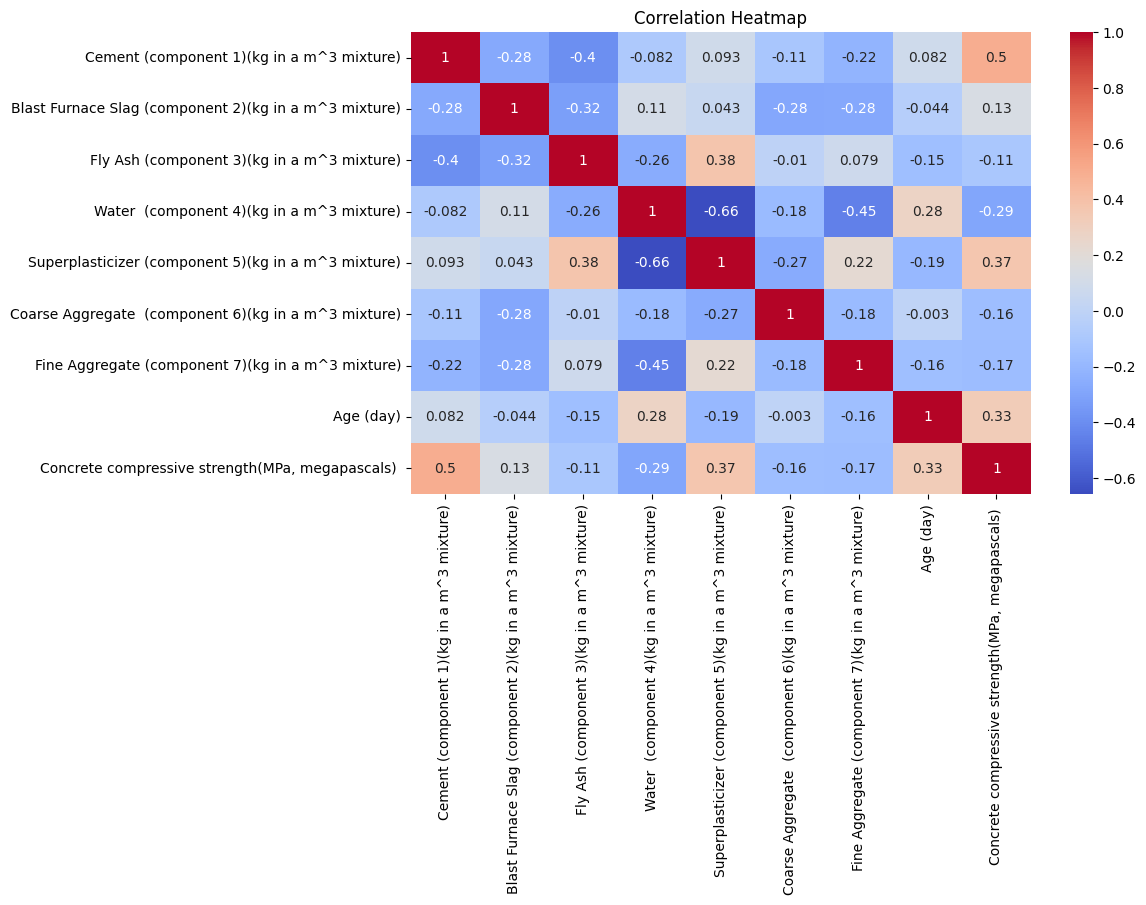

In [4]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
pca = PCA()
pca.fit(X_train)
variance = pca.explained_variance_ratio_
print("Explained Variance:")
print(variance)


Explained Variance:
[0.2801617  0.17910071 0.16830488 0.12802833 0.11812444 0.099379
 0.02301989 0.00388105]


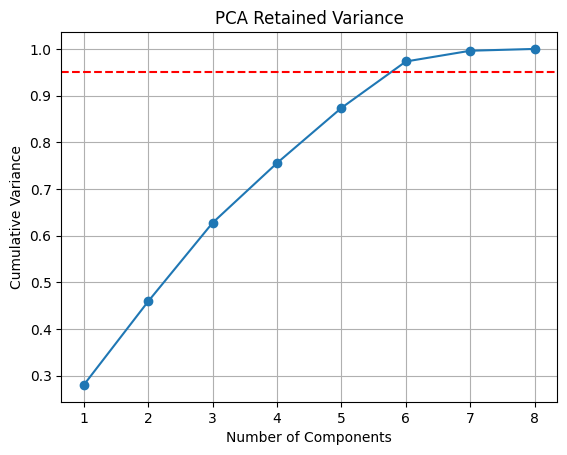

Components needed for 95% variance: 6


In [6]:
cumulative = np.cumsum(variance)
plt.plot(range(1, 9), cumulative, marker='o')
plt.axhline(0.95, color='red', linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance")
plt.title("PCA Retained Variance")
plt.grid()
plt.show()
n = np.argmax(cumulative >= 0.95) + 1
print("Components needed for 95% variance:", n)

In [ ]:
##Without pca

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
model1 = LinearRegression()
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)
rmse1 = np.sqrt(mean_squared_error(y_test, pred1))
r2_1 = r2_score(y_test, pred1)
print("RMSE:", rmse1)
print("R2 Score:", r2_1)

RMSE: 9.796707832398445
R2 Score: 0.6275416055429022


In [ ]:
##With pca

In [15]:
# Display PCA component coefficients
coefficients = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(n)]
)

print(coefficients.round(3))
for i, weights in enumerate(pca.components_):
    equation = f"PC{i+1} = "

    terms = [
        f"({weight:.3f} × {feature})"
        for weight, feature in zip(weights, X.columns)
    ]

    equation += " + ".join(terms)
    print(equation)
    print()

     Cement (component 1)(kg in a m^3 mixture)  \
PC1                                      0.121   
PC2                                     -0.276   
PC3                                      0.760   
PC4                                     -0.092   
PC5                                     -0.118   
PC6                                     -0.234   

     Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
PC1                                              0.144       
PC2                                              0.709       
PC3                                             -0.041       
PC4                                             -0.375       
PC5                                              0.041       
PC6                                              0.298       

     Fly Ash (component 3)(kg in a m^3 mixture)  \
PC1                                      -0.395   
PC2                                      -0.117   
PC3                                      -0.446   
PC4       

In [16]:
for i, value in enumerate(pca.explained_variance_ratio_):
    print(f"PC{i+1}: {value * 100:.2f}%")

PC1: 28.02%
PC2: 17.91%
PC3: 16.83%
PC4: 12.80%
PC5: 11.81%
PC6: 9.94%


In [17]:
# Original standardized first training sample
print("Standardized ingredients:")
print(X_train[0])

# Converted PCA values
print("\nPrincipal Component Scores:")
print(pca.transform(X_train[0].reshape(1, -1))[0])

Standardized ingredients:
[-1.16084578  0.85739475  0.9824742  -0.31423092  1.48199143 -0.25745695
 -0.64750466 -0.27567315]

Principal Component Scores:
[-1.17558232  1.22124279 -0.83648073 -0.73822532 -1.20601286  0.29323194]


In [8]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train)

variance = pca.explained_variance_ratio_

print("Explained Variance:")
print(variance)

Explained Variance:
[0.2801617  0.17910071 0.16830488 0.12802833 0.11812444 0.099379
 0.02301989 0.00388105]


In [9]:
from sklearn.decomposition import PCA
pca_selected = PCA(n_components=n)
pca_selected.fit(X_train)
loadings = pd.DataFrame(
    pca_selected.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(n)]
)
importance = (loadings ** 2) @ pca_selected.explained_variance_ratio_
importance = importance.sort_values(ascending=False)
print("Feature Contributions:")
print(importance)
print("\nLeast Contributing Features:")
print(importance.tail(3))

Feature Contributions:
Age (day)                                                0.124897
Fine Aggregate (component 7)(kg in a m^3 mixture)        0.124210
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0.123268
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0.123089
Cement (component 1)(kg in a m^3 mixture)                0.123087
Fly Ash (component 3)(kg in a m^3 mixture)               0.121577
Water  (component 4)(kg in a m^3 mixture)                0.118076
Superplasticizer (component 5)(kg in a m^3 mixture)      0.114896
dtype: float64

Least Contributing Features:
Fly Ash (component 3)(kg in a m^3 mixture)             0.121577
Water  (component 4)(kg in a m^3 mixture)              0.118076
Superplasticizer (component 5)(kg in a m^3 mixture)    0.114896
dtype: float64


In [10]:
pca = PCA(n_components=n)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model2 = LinearRegression()
model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)

rmse2 = np.sqrt(mean_squared_error(y_test, pred2))
r2_2 = r2_score(y_test, pred2)

print("RMSE:", rmse2)
print("R2 Score:", r2_2)

RMSE: 10.551507514163907
R2 Score: 0.5679375943145377


In [11]:
from sklearn.metrics import mean_absolute_error

mae1 = mean_absolute_error(y_test, pred1)
mae2 = mean_absolute_error(y_test, pred2)

print("MAE Without PCA:", mae1)
print("MAE With PCA:", mae2)

MAE Without PCA: 7.745392872421345
MAE With PCA: 8.487613218614968


In [ ]:
#Compare

In [13]:
results = pd.DataFrame({
    "Model": ["Without PCA", "With PCA"],
    "Features": [8, n],
    "MAE": [mae1, mae2],
    "RMSE": [rmse1, rmse2],
    "R2 Score": [r2_1, r2_2]
})

results


,Model,Features,MAE,RMSE,R2 Score
0,Without PCA,8,7.745393,9.796708,0.627542
1,With PCA,6,8.487613,10.551508,0.567938


In [14]:
retained = cumulative[n-1] * 100
lost = 100 - retained

print("Retained Variance:", round(retained, 2), "%")
print("Lost Variance:", round(lost, 2), "%")

Retained Variance: 97.31 %
Lost Variance: 2.69 %


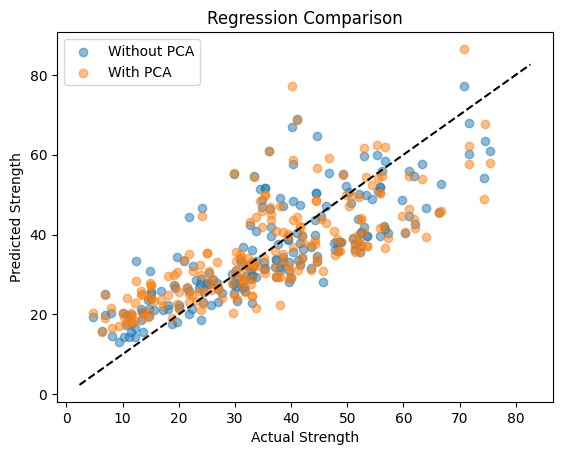

In [ ]:
plt.scatter(y_test, pred1, label="Without PCA", alpha=0.5)
plt.scatter(y_test, pred2, label="With PCA", alpha=0.5)

plt.plot([y.min(), y.max()],
         [y.min(), y.max()], 'k--')

plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")
plt.title("Regression Comparison")
plt.legend()
plt.show()

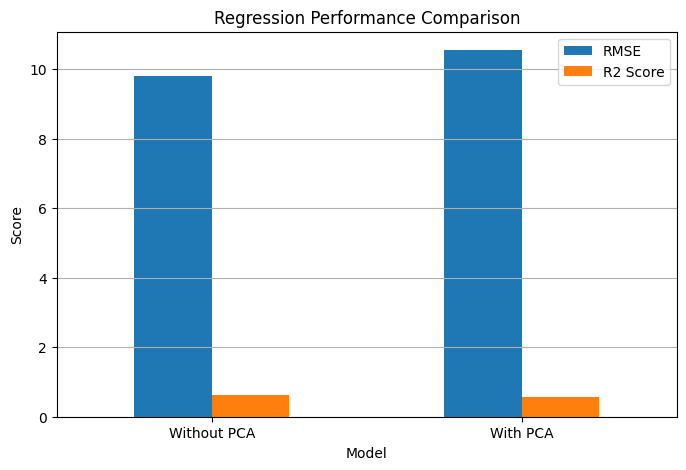

In [ ]:
results.set_index("Model")[["RMSE", "R2 Score"]].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Regression Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [ ]:
loadings = pd.DataFrame(
    pca.components_[:n].T,
    columns=[f"PC{i+1}" for i in range(n)],
    index=X.columns
)

print(loadings.round(3))


                                                      PC1    PC2    PC3  \
Cement (component 1)(kg in a m^3 mixture)           0.121 -0.276  0.760   
Blast Furnace Slag (component 2)(kg in a m^3 mi...  0.144  0.709 -0.041   
Fly Ash (component 3)(kg in a m^3 mixture)         -0.395 -0.117 -0.446   
Water  (component 4)(kg in a m^3 mixture)           0.545  0.115 -0.217   
Superplasticizer (component 5)(kg in a m^3 mixt... -0.514  0.188  0.284   
Coarse Aggregate  (component 6)(kg in a m^3 mix...  0.061 -0.587 -0.288   
Fine Aggregate (component 7)(kg in a m^3 mixture)  -0.400  0.027  0.025   
Age (day)                                           0.290 -0.117  0.103   

                                                      PC4    PC5    PC6  
Cement (component 1)(kg in a m^3 mixture)          -0.092 -0.118 -0.234  
Blast Furnace Slag (component 2)(kg in a m^3 mi... -0.375  0.041  0.298  
Fly Ash (component 3)(kg in a m^3 mixture)          0.114 -0.553 -0.203  
Water  (component 4)(kg in a